# Map Converter
This is a Jupyter Notebook to Convert a `.png` or `.pgm` + `.yaml` of a map into a `.csv` that can be fed into the TUMFTM functions.

High Level Steps:
1. Get the Euclidean Distance Transform of the map
2. Apply skeletonization to the map to extract centerlines
3. Run DFS to extract the centerline xy coordinates in order
4. Apply the transformations to go from pixel to meter coordinate frame


Map Conditions:
- Map edges should be well defined, inside should be white, walls are black and outside is grey

In [1]:
import numpy as np
from skimage.morphology import skeletonize
import matplotlib.pyplot as plt
import yaml
import scipy
from scipy.ndimage import distance_transform_edt as edt
from PIL import Image
import os

In [2]:
MAP_NAME = "e7_fifth_big_raceline"

TRACK_WIDTH_MARGIN = 0.0 # Extra Safety margin, in meters

# Centerline smoothing / resampling (see the smoothing cell further down).
# The raw skeleton centerline is pixel-quantized (jagged, ~1 px spacing). Smoothing +
# uniform arc-length resampling removes the staircase noise, and a curvature-based width
# clamp fixes distance-transform widths that are physically too large at tight hairpins
# (where half-width > turn radius, the track boundary folds and the optimizer throws
# "spline normals are crossed"). With a clean centerline you get a dense, smooth raceline
# through hairpins without inflating the stepsizes in params/f110.ini.
SMOOTHING = 1.0        # scipy splprep smoothing factor `s`. Higher -> smoother (further
                       # from the raw skeleton); lower -> hugs the raw points more.
RESAMPLE_STEP = 0.1    # [m] target arc-length spacing of the output centerline points.
WIDTH_CURV_FRAC = 0.9  # cap each half-width at this fraction of the local turn radius so a
                       # corner of radius R never claims more than WIDTH_CURV_FRAC*R of
                       # lateral room (prevents the boundary fold at hairpins). Lower this
                       # if the "spline normals are crossed" error still fires; set to None
                       # to disable the clamp.

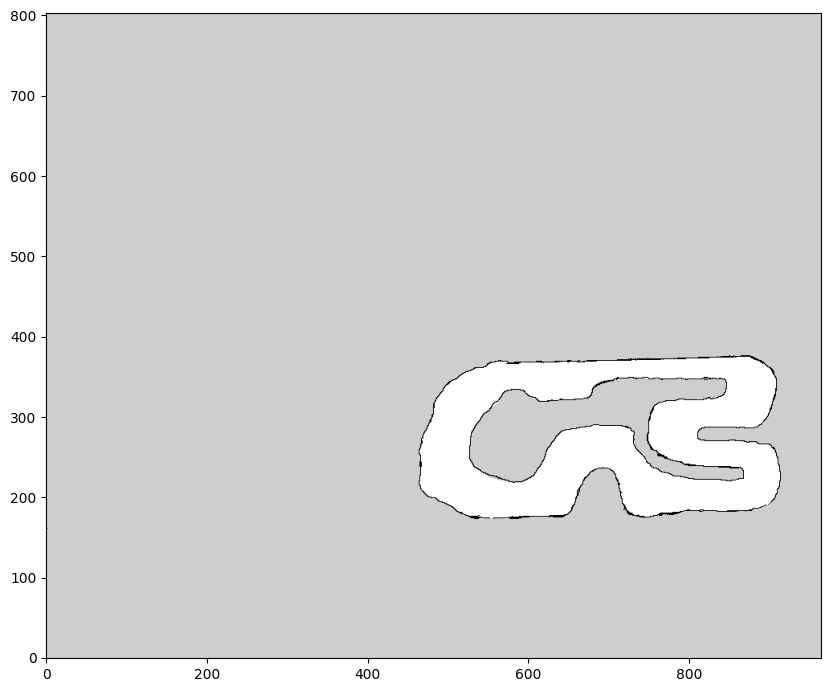

In [3]:
# Modified from https://github.com/CL2-UWaterloo/Head-to-Head-Autonomous-Racing/blob/main/gym/f110_gym/envs/laser_models.py
# load map image

if os.path.exists(f"maps/{MAP_NAME}.png"):
    map_img_path = f"maps/{MAP_NAME}.png"
elif os.path.exists(f"maps/{MAP_NAME}.pgm"):
    map_img_path = f"maps/{MAP_NAME}.pgm"
else:
    raise Exception("Map not found!")

map_yaml_path = f"maps/{MAP_NAME}.yaml"
raw_map_img = np.array(Image.open(map_img_path).transpose(Image.FLIP_TOP_BOTTOM))
raw_map_img = raw_map_img.astype(np.float64)

plt.figure(figsize=(10, 10))
plt.imshow(raw_map_img, cmap='gray', origin='lower')

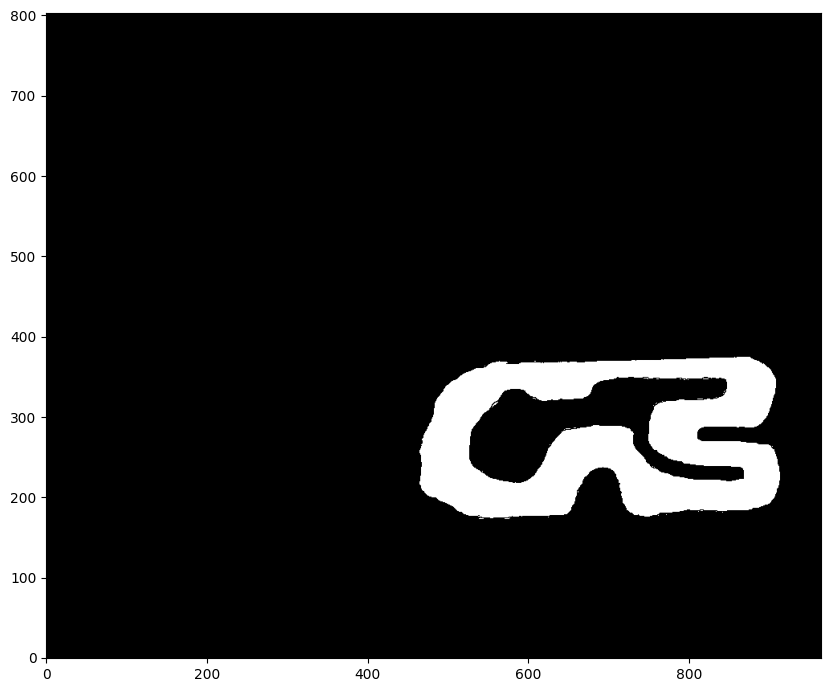

In [4]:
# grayscale -> binary. Converts grey to black
map_img = raw_map_img.copy()
map_img[map_img <= 210.] = 0
map_img[map_img > 210.] = 1

map_height = map_img.shape[0]
# map_width = map_img.shape[1]
map_img
plt.figure(figsize=(10, 10))
plt.imshow(map_img, cmap='gray', origin='lower')

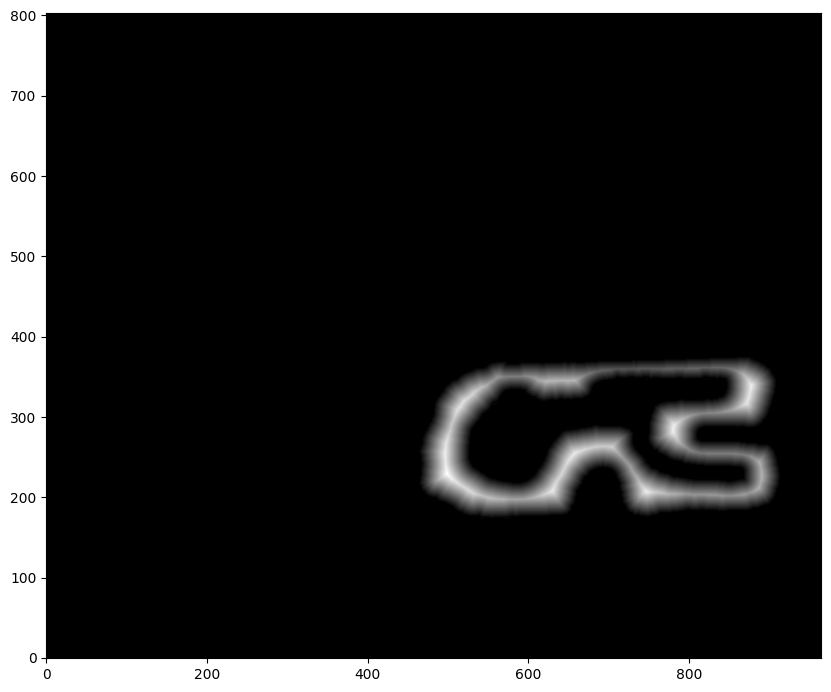

In [5]:
plt.figure(figsize=(10, 10))
# Calculate Euclidean Distance Transform (tells us distance to nearest wall)
dist_transform = scipy.ndimage.distance_transform_edt(map_img)
plt.imshow(dist_transform, cmap='gray', origin='lower')

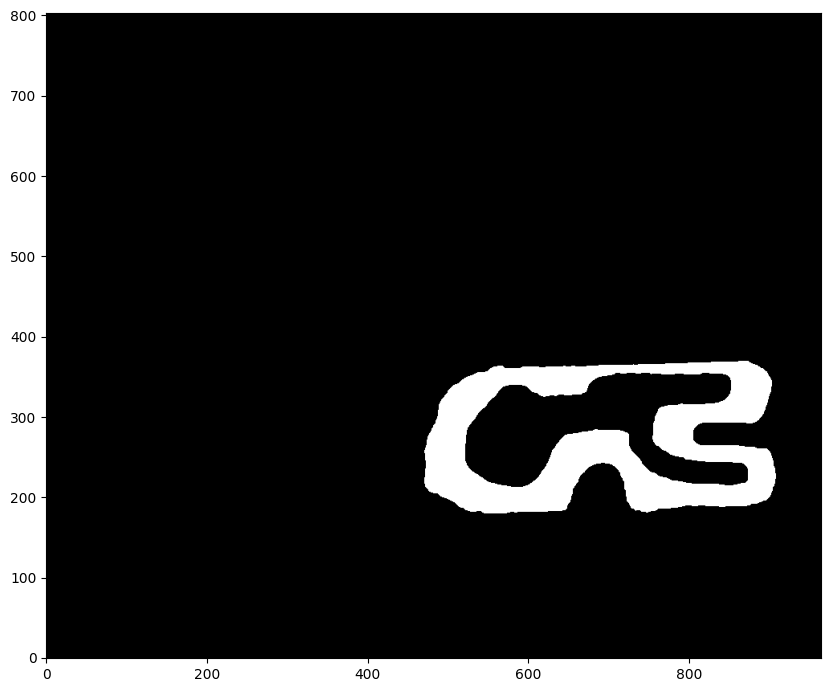

In [6]:

# Threshold the distance transform to create a binary image
THRESHOLD = 0.17 # You should play around with this number. Is you say hairy lines generated, either clean the map so it is more curvy or increase this number
centers = dist_transform > THRESHOLD*dist_transform.max()
plt.figure(figsize=(10, 10))
plt.imshow(centers, origin='lower', cmap='gray')

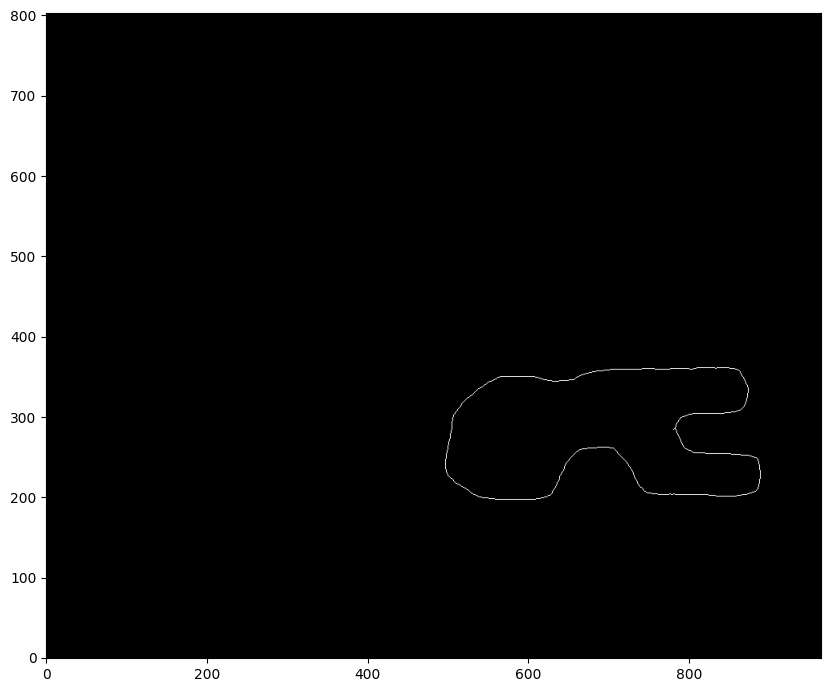

In [7]:
plt.figure(figsize=(10, 10))
centerline = skeletonize(centers)
plt.imshow(centerline, origin='lower', cmap='gray')

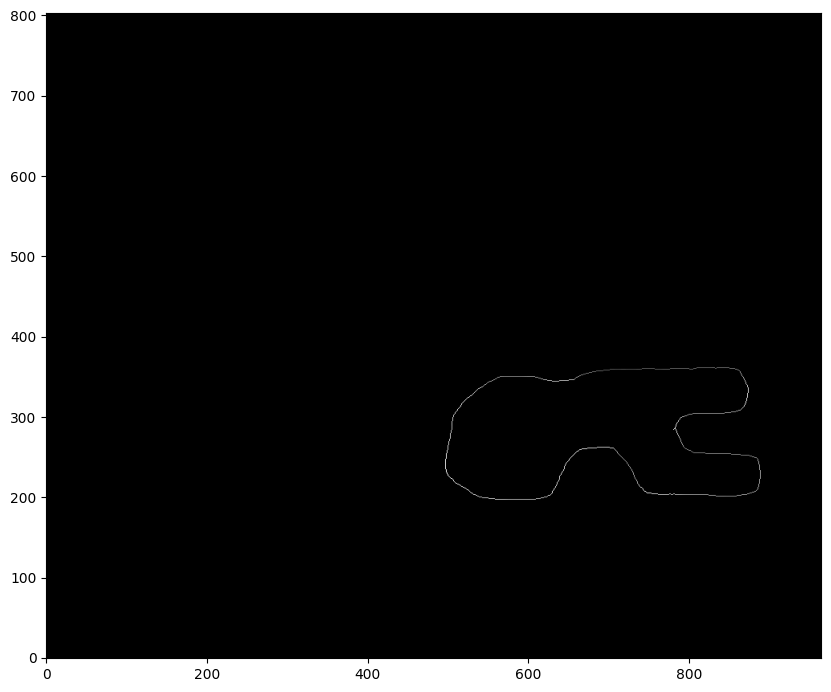

In [8]:
# The centerline has the track width encoded
plt.figure(figsize=(10, 10))
centerline_dist = np.where(centerline, dist_transform, 0)
plt.imshow(centerline_dist, origin='lower', cmap='gray')

In [9]:
LEFT_START_Y = map_height // 2 - 120

In [10]:
NON_EDGE = 0.0
# Use DFS to extract the outer edge
left_start_y = LEFT_START_Y
left_start_x = 0
while (centerline_dist[left_start_y][left_start_x] == NON_EDGE): 
	left_start_x += 1

print(f"Starting position for left edge: {left_start_x} {left_start_y}")

Starting position for left edge: 504 281


In [11]:
# Run DFS
import sys
sys.setrecursionlimit(20000)

visited = {}
centerline_points = []
track_widths = []
# DIRECTIONS = [(0, 1), (1, 0), (0, -1), (-1, 0), (1, 1), (1, -1), (-1, 1), (-1, -1)]
# If you want the other direction first
DIRECTIONS = [(0, -1), (-1, 0),  (0, 1), (1, 0), (-1, 1), (-1, -1), (1, 1), (1, -1) ]

starting_point = (left_start_x, left_start_y)

def dfs(point):
	if (point in visited): return
	visited[point] = True
	centerline_points.append(np.array(point))
	track_widths.append(np.array([centerline_dist[point[1]][point[0]], centerline_dist[point[1]][point[0]]]))

	for direction in DIRECTIONS:
		if (centerline_dist[point[1] + direction[1]][point[0] + direction[0]] != NON_EDGE and (point[0] + direction[0], point[1] + direction[1]) not in visited):
			dfs((point[0] + direction[0], point[1] + direction[1]))

dfs(starting_point)

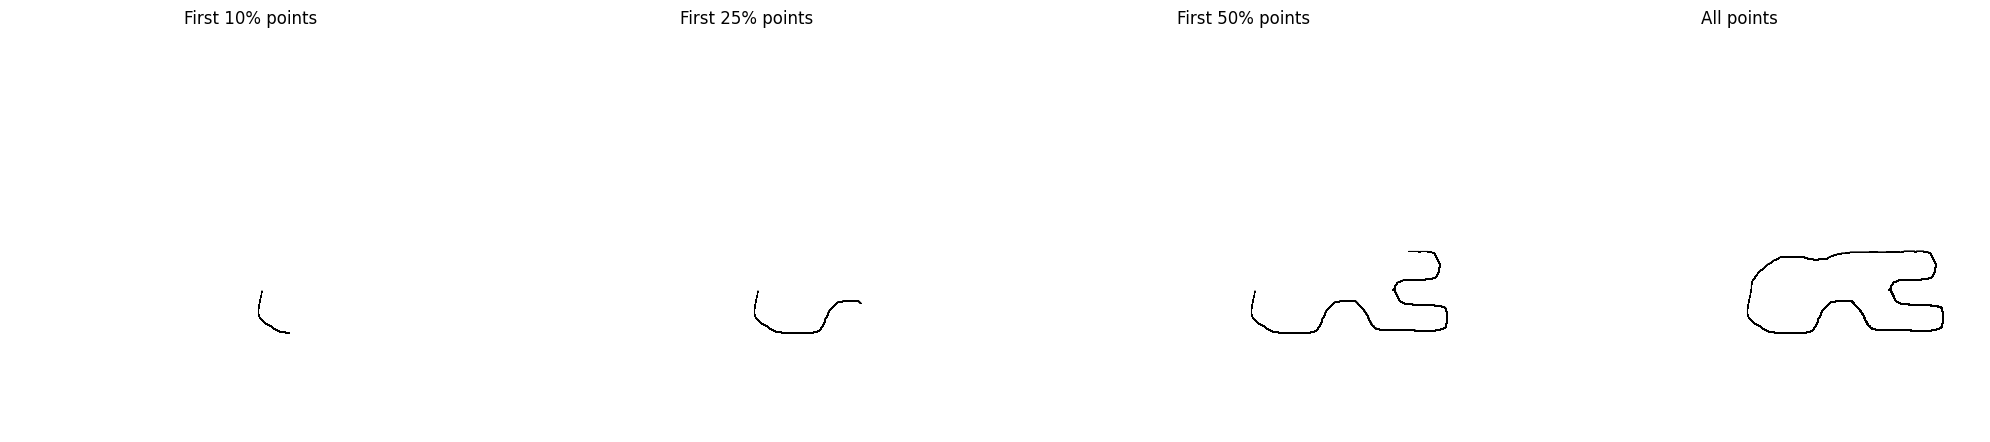

In [12]:
fig, (ax1,ax2,ax3, ax4) = plt.subplots(1, 4, figsize=(20,5))
ax1.axis('off')
ax2.axis('off')
ax3.axis('off')
ax4.axis('off')

centerline_img = np.zeros(map_img.shape)
for x,y in centerline_points[:len(centerline_points)//10]:
	centerline_img[y][x] = 255
ax1.imshow(centerline_img, cmap='Greys', vmax=1, origin='lower')
ax1.set_title("First 10% points")

centerline_img = np.zeros(map_img.shape)
for x,y in centerline_points[:len(centerline_points)//4]:
	centerline_img[y][x] = 255
ax2.imshow(centerline_img, cmap='Greys', vmax=1, origin='lower')
ax2.set_title("First 25% points")

centerline_img = np.zeros(map_img.shape)
for x,y in centerline_points[:int(len(centerline_points)/1.4)]:
	centerline_img[y][x] = 255
ax3.imshow(centerline_img, cmap='Greys', vmax=1, origin='lower')
ax3.set_title("First 50% points")

centerline_img = np.zeros(map_img.shape)
for x,y in centerline_points:
	centerline_img[y][x] = 1000
ax4.imshow(centerline_img, cmap='Greys', vmax=1, origin='lower')
ax4.set_title("All points")
fig.tight_layout()

# Conversion
Convert into Pandas, and go from pixels to meters, and then shift by the origin.

In [64]:
track_widths

[array([24.73863375, 24.73863375]),
 array([24.51530134, 24.51530134]),
 array([25.3179778, 25.3179778]),
 array([25.17935662, 25.17935662]),
 array([25.07987241, 25.07987241]),
 array([25.01999201, 25.01999201]),
 array([25., 25.]),
 array([25., 25.]),
 array([25., 25.]),
 array([26., 26.]),
 array([25.96150997, 25.96150997]),
 array([25.70992026, 25.70992026]),
 array([26.47640459, 26.47640459]),
 array([26.30589288, 26.30589288]),
 array([26.17250466, 26.17250466]),
 array([26.07680962, 26.07680962]),
 array([26.01922366, 26.01922366]),
 array([27., 27.]),
 array([27., 27.]),
 array([27., 27.]),
 array([27., 27.]),
 array([27., 27.]),
 array([27., 27.]),
 array([28., 28.]),
 array([28., 28.]),
 array([28., 28.]),
 array([28., 28.]),
 array([29., 29.]),
 array([29., 29.]),
 array([29., 29.]),
 array([29., 29.]),
 array([29., 29.]),
 array([29., 29.]),
 array([29., 29.]),
 array([30., 30.]),
 array([30.01666204, 30.01666204]),
 array([30.06659276, 30.06659276]),
 array([30.01666204, 3

In [13]:
track_widths_np = np.array(track_widths)
waypoints = np.array(centerline_points)
print(f"Track widths shape: {track_widths_np.shape}, waypoints shape: {waypoints.shape}")

Track widths shape: (1150, 2), waypoints shape: (1150, 2)


In [14]:
# Merge track with waypoints
data = np.concatenate((waypoints, track_widths_np), axis=1)
data.shape

(1150, 4)

In [15]:
# load map yaml
with open(map_yaml_path, 'r') as yaml_stream:
    try:
        map_metadata = yaml.safe_load(yaml_stream)
        map_resolution = map_metadata['resolution']
        origin = map_metadata['origin']
    except yaml.YAMLError as ex:
        print(ex)

# calculate map parameters
orig_x = origin[0]
orig_y = origin[1]
# ??? Should be 0
orig_s = np.sin(origin[2])
orig_c = np.cos(origin[2])

# get the distance transform
transformed_data = data
transformed_data *= map_resolution
transformed_data += np.array([orig_x, orig_y, 0, 0])

# Safety margin
transformed_data -= np.array([0, 0, TRACK_WIDTH_MARGIN, TRACK_WIDTH_MARGIN])

Width clamp: 69/604 points reduced (tightest radius 0.53 m, min half-width now 0.48 m)
Centerline: 1150 raw points -> 604 resampled points (loop length 60.4 m, ~0.1 m spacing)


/home/muta/miniconda3/envs/wato/lib/python3.7/site-packages/scipy/interpolate/_fitpack_impl.py:226: RuntimeWarning: Setting x[1][1150]=x[1][0]
  (i, m, i)))


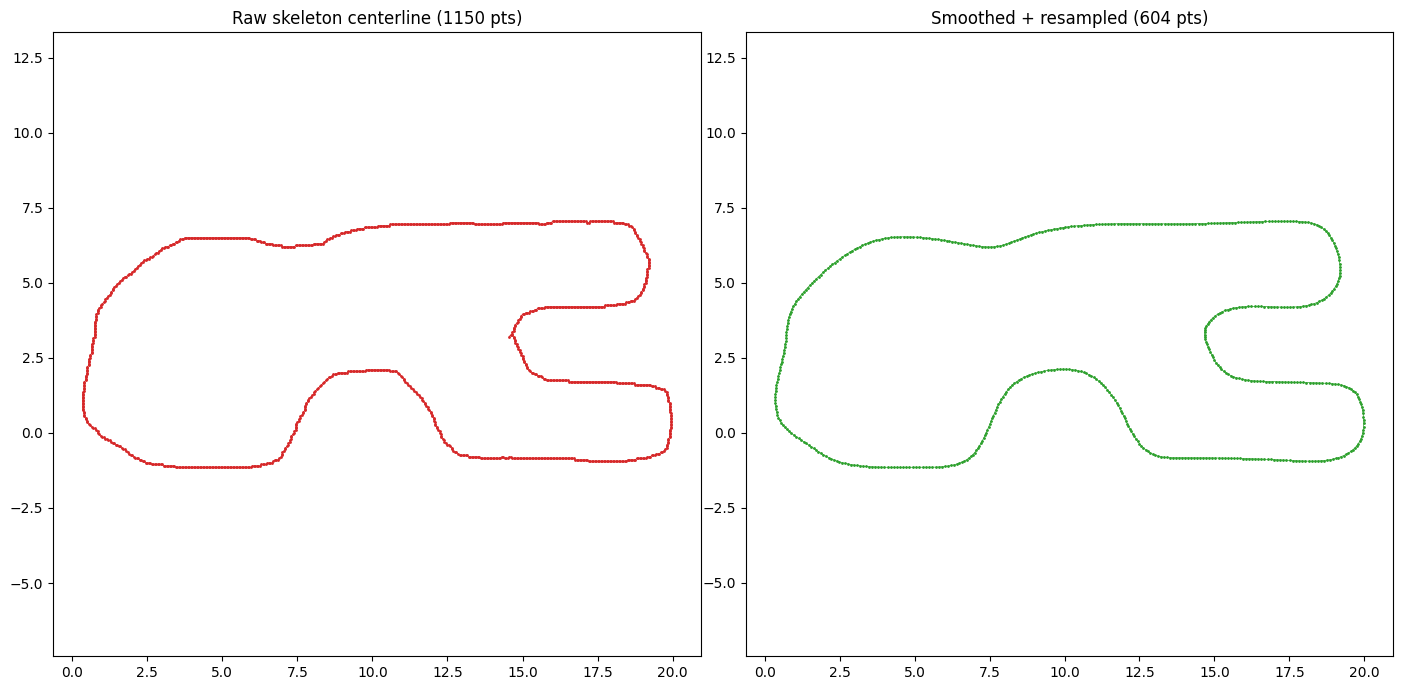

In [16]:
# Smooth + uniformly resample the centerline, then clamp widths against local curvature.
#
# Replaces the old `transformed_data = transformed_data[::4]` hack. The raw skeleton
# centerline is jagged (pixel-quantized) and its distance-transform widths are over-large at
# tight hairpins, both of which make adjacent spline normals cross in the optimizer ->
# `IOError("At least two spline normals are crossed ...")`. Fitting a periodic smoothing
# spline + resampling at uniform arc length removes the noise; capping each half-width at a
# fraction of the local turn radius removes the boundary fold at hairpins. The result lets
# you use a SMALL stepsize in params/f110.ini for a dense, smooth raceline.
from scipy import interpolate

raw_data = transformed_data.copy()          # keep the jagged version for the before/after plot
xy = raw_data[:, :2]
widths = raw_data[:, 2:]

# Fit a periodic (closed-loop) cubic smoothing spline through the ordered centerline points.
# per=1 closes the loop, so do NOT append the first point manually.
tck, u = interpolate.splprep([xy[:, 0], xy[:, 1]], per=1, k=3, s=SMOOTHING)

# Estimate total loop length by densely evaluating the spline.
u_dense = np.linspace(0.0, 1.0, 2000)
dense_pts = np.array(interpolate.splev(u_dense, tck)).T
length = np.sum(np.sqrt(np.sum(np.diff(dense_pts, axis=0) ** 2, axis=1)))

# Resample at uniform arc-length spacing (endpoint dropped so the loop is not duplicated).
n_points = max(int(round(length / RESAMPLE_STEP)), 10)
u_new = np.linspace(0.0, 1.0, n_points, endpoint=False)
x_new, y_new = interpolate.splev(u_new, tck)

# Re-map track widths onto the new sampling against the spline parameter u (period=1 handles
# the wraparound), so widths stay aligned to the geometry.
wr_new = np.interp(u_new, u, widths[:, 0], period=1.0)
wl_new = np.interp(u_new, u, widths[:, 1], period=1.0)

# Curvature-based width clamp. Use the spline's exact 1st/2nd derivatives (w.r.t. u) to get
# the local turn radius R = (x'^2 + y'^2)^1.5 / |x'y'' - y'x''| (parameterization-invariant),
# then cap each half-width at WIDTH_CURV_FRAC * R so no corner claims more room than it has.
if WIDTH_CURV_FRAC is not None:
    dx, dy = interpolate.splev(u_new, tck, der=1)
    ddx, ddy = interpolate.splev(u_new, tck, der=2)
    cross = np.abs(dx * ddy - dy * ddx)
    radius = np.where(cross > 1e-9, np.power(dx * dx + dy * dy, 1.5) / cross, np.inf)
    cap = WIDTH_CURV_FRAC * radius
    n_clamped = int(np.sum((wr_new > cap) | (wl_new > cap)))
    wr_new = np.minimum(wr_new, cap)
    wl_new = np.minimum(wl_new, cap)
    print(f"Width clamp: {n_clamped}/{n_points} points reduced (tightest radius "
          f"{np.min(radius):.2f} m, min half-width now {min(wr_new.min(), wl_new.min()):.2f} m)")

transformed_data = np.column_stack([x_new, y_new, wr_new, wl_new])
print(f"Centerline: {len(raw_data)} raw points -> {len(transformed_data)} resampled points"
      f" (loop length {length:.1f} m, ~{RESAMPLE_STEP} m spacing)")

# Before/after preview so the smoothing effect is visible.
fig, (axr, axs) = plt.subplots(1, 2, figsize=(14, 7))
axr.plot(xy[:, 0], xy[:, 1], '.-', ms=2, lw=0.5, color='tab:red')
axr.set_title(f"Raw skeleton centerline ({len(raw_data)} pts)")
axr.set_aspect('equal', 'datalim')
axs.plot(transformed_data[:, 0], transformed_data[:, 1], '.-', ms=2, lw=0.5, color='tab:green')
axs.set_title(f"Smoothed + resampled ({len(transformed_data)} pts)")
axs.set_aspect('equal', 'datalim')
fig.tight_layout()

In [17]:
with open(f"inputs/tracks/{MAP_NAME}.csv", 'wb') as fh:
    np.savetxt(fh, transformed_data, fmt='%0.4f', delimiter=',', header='x_m,y_m,w_tr_right_m,w_tr_left_m')

Next up, check out `sanity_check.ipynb` to make sure that the centerline generated lines up with the map.